# Single-cell RNA-seq of the human intestine: QC, scVI integration and cell-type annotation

scanpy workflow: QC metrics and filtering, Scrublet doublet detection, normalisation, highly variable genes, PCA/UMAP, scVI batch integration across samples, CellTypist annotation (Adult_Human_Intestine model), Leiden clustering and marker genes.


In [ ]:
# Imports
from pathlib import Path
import pandas as pd
import scanpy as sc
import scanpy as sc

import scvi
import celltypist
from celltypist import models
import matplotlib.pyplot as plt
 
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
 

In [36]:
# Data Loading
data_folder = Path("/data/GTA_data/single_cell/")

subset_path = Path(f"{data_folder}/multi_tissue-atlas_subsample.h5ad")
metadata_path = Path(f"{data_folder}/sample_metadata.tsv")

metadata_df = pd.read_csv(metadata_path, sep='\t')
subset = sc.read_h5ad(subset_path)

print(metadata_df)
subset

      sanger_sample_id     biopsy_type bead_version    bead_lot chip_version  \
0     5892STDY10205765  terminal ileum         V3.1         NaN       chip-g   
1     5892STDY10315937  terminal ileum         V3.1  lot_160848       chip-g   
2     5892STDY10315938  terminal ileum         V3.1  lot_160848       chip-g   
3     5892STDY10653007  terminal ileum         V3.1  lot_160848       chip-g   
4     5892STDY10653009  terminal ileum         V3.1  lot_160848       chip-g   
..                 ...             ...          ...         ...          ...   
731  OTARscRNA11395198  terminal ileum         V3.1  lot_160848       chip-g   
732  OTARscRNA11395199          rectum         V3.1  lot_160848       chip-g   
733  OTARscRNA14592798  terminal ileum         V3.1  lot_201316       chip-g   
734  OTARscRNA14592808          rectum         V3.1  lot_201415       chip-g   
735  OTARscRNA11765486          rectum         V3.1  lot_160916       chip-g   

       chip_lot enzyme_lot_BLP     gem_

AnnData object with n_obs × n_vars = 15043 × 33538
    obs: 'sanger_sample_id', 'tissue'
    var: 'gene_symbols', 'feature_types'

In [37]:
# Data merging
data_df = pd.merge(subset.obs, metadata_df, on="sanger_sample_id")

data_df

,sanger_sample_id,tissue,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot
0,5892STDY10315937,ti,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900
1,5892STDY10315937,ti,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900
2,5892STDY10315937,ti,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900
3,5892STDY10315937,ti,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900
4,5892STDY10315937,ti,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900
...,...,...,...,...,...,...,...,...,...
15038,5892STDY14188989,ti,terminal ileum,V3.1,lot_201193,chip-g,lot_201758,SLCP0325,lot_201078
15039,5892STDY14188989,ti,terminal ileum,V3.1,lot_201193,chip-g,lot_201758,SLCP0325,lot_201078
15040,5892STDY14188989,ti,terminal ileum,V3.1,lot_201193,chip-g,lot_201758,SLCP0325,lot_201078
15041,5892STDY14188989,ti,terminal ileum,V3.1,lot_201193,chip-g,lot_201758,SLCP0325,lot_201078


In [38]:
# Check how many cells per sample
data_df['sanger_sample_id'].value_counts()

# Or check tissue distribution
data_df['tissue'].value_counts()

# Or check biopsy type distribution
data_df['biopsy_type'].value_counts()

biopsy_type
terminal ileum    15043
Name: count, dtype: int64

In [39]:
#There is no need to asign a unique barcode because we have onlz one data frame so after merging the data frame with the metadata we are good to go
#there is also no need to filter the data out bz cells and genes cause there is onlz one tisue and one biopsy type

#in case this was necessary 
# Filter cells and genes

print("\nCell filtering")
print(subset.obs.value_counts("sanger_sample_id"))
sc.pp.filter_cells(subset, min_counts=100)
print(subset.obs.value_counts("sanger_sample_id"))


Cell filtering
sanger_sample_id
5892STDY10315938    5509
5892STDY13265994    5032
5892STDY14188989    2886
5892STDY10315937    1616
Name: count, dtype: int64
sanger_sample_id
5892STDY10315938    5509
5892STDY13265994    5032
5892STDY14188989    2886
5892STDY10315937    1616
Name: count, dtype: int64


In [9]:
# Save the full AnnData object (not necessary if already loaded)
# subset.write_h5ad("/data/GTA_data/single_cell/subset_full.h5ad")

# Check the object
subset

# Subsample data (not necessary - our dataset is already small enough)
# adata_sub = sc.pp.subsample(subset, fraction=0.05, copy=True)
# adata_sub

# Save subsample (not necessary)
# subset_sub.write_h5ad("/data/GTA_data/single_cell/subset_subsample.h5ad")

AnnData object with n_obs × n_vars = 15043 × 33538
    obs: 'sanger_sample_id', 'tissue', 'n_counts'
    var: 'gene_symbols', 'feature_types'

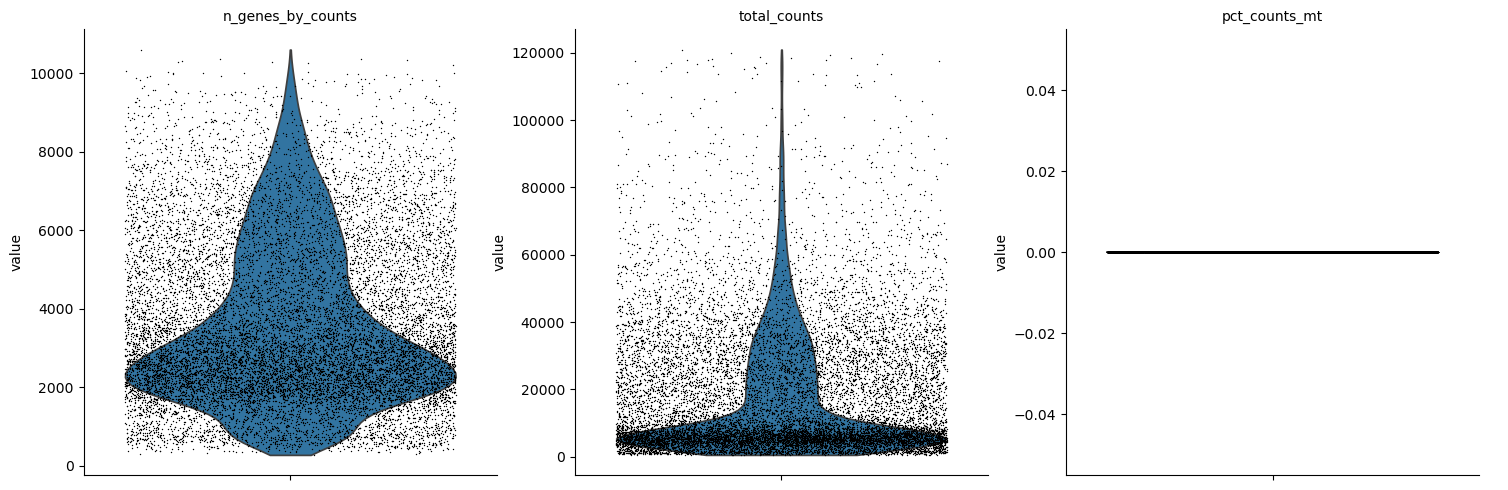

In [41]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
subset.var["mt"] = subset.var_names.str.startswith("MT-")
# ribosomal genes
subset.var["ribo"] = subset.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
subset.var["hb"] = subset.var_names.str.contains("^HB[^(P)]")

# Calculate QC metrics
sc.pp.calculate_qc_metrics(subset, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

# Plot QC violin plots
sc.pl.violin(
    subset,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

### Violin plots
1. n_genes_by_counts — Number of genes per cell
Most cells detect ~2,000–3,000 genes (the wide belly of the violin)
Some cells go up to 10,000+ → possible doublets (two cells in one droplet)
A few cells very low → possible empty droplets/debris
Overall looks healthy

2. total_counts — Total RNA counts per cell
Most cells cluster at the bottom (~5,000–20,000 counts) — normal
A long tail of cells with very high counts (>80,000) likely doublets

3. pct_counts_mt — % Mitochondrial counts
This is essentially 0 for all cells (flat line at 0)
The dataset was already pre-filtered for MT content


In [42]:
sc.pp.scrublet(subset, batch_key="sanger_sample_id")
subset.obs.describe()

,n_counts,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb,n_genes,doublet_score
count,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.000000,15043.000000
mean,18050.480469,3570.413215,8.000357,18050.480469,9.272897,35.728158,43.613111,51.801384,65.050929,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3569.328724,0.032627
std,18735.500000,2048.328378,0.635984,18735.500000,1.080135,15.402620,14.387091,13.129271,11.840876,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2047.683369,0.035808
min,504.000000,271.000000,5.605802,504.000000,6.224558,13.000342,18.795291,26.622471,41.188707,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.000000,0.002411
25%,4987.000000,2063.500000,7.632643,4987.000000,8.514791,25.993710,34.023469,42.698812,56.568293,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2063.000000,0.013220
50%,9176.000000,3004.000000,8.008033,9176.000000,9.124455,31.752752,40.473698,49.009268,62.309618,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3004.000000,0.021941
75%,27379.500000,4913.000000,8.499844,27379.500000,10.217587,39.142902,48.352945,57.140950,70.679685,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4911.500000,0.040253
max,120978.000000,10600.000000,9.268704,120978.000000,11.703372,94.011490,94.860747,95.945215,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10594.000000,0.491071


In [43]:
#Data Normalization
# Saving count data
subset.layers["counts"] = subset.X.copy()

In [44]:
# Normalizing to median total counts
sc.pp.normalize_total(subset)

# Logarithmize the data
sc.pp.log1p(subset)

In [45]:
sc.pp.highly_variable_genes(subset, n_top_genes=2000, batch_key="sanger_sample_id")

In [46]:
subset.obs.describe()

,n_counts,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb,n_genes,doublet_score
count,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.000000,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.0,15043.000000,15043.000000
mean,18050.480469,3570.413215,8.000357,18050.480469,9.272897,35.728158,43.613111,51.801384,65.050929,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3569.328724,0.032627
std,18735.500000,2048.328378,0.635984,18735.500000,1.080135,15.402620,14.387091,13.129271,11.840876,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2047.683369,0.035808
min,504.000000,271.000000,5.605802,504.000000,6.224558,13.000342,18.795291,26.622471,41.188707,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.000000,0.002411
25%,4987.000000,2063.500000,7.632643,4987.000000,8.514791,25.993710,34.023469,42.698812,56.568293,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2063.000000,0.013220
50%,9176.000000,3004.000000,8.008033,9176.000000,9.124455,31.752752,40.473698,49.009268,62.309618,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3004.000000,0.021941
75%,27379.500000,4913.000000,8.499844,27379.500000,10.217587,39.142902,48.352945,57.140950,70.679685,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4911.500000,0.040253
max,120978.000000,10600.000000,9.268704,120978.000000,11.703372,94.011490,94.860747,95.945215,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10594.000000,0.491071


In [47]:
sc.tl.pca(subset)

In [48]:
sc.pp.neighbors(subset)

In [49]:
print(subset.obs.value_counts("predicted_doublet"))
subset.obs

predicted_doublet
False    15038
True         5
Name: count, dtype: int64


,sanger_sample_id,tissue,n_counts,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb,n_genes,doublet_score,predicted_doublet
CTGAGGCAGGATTTCC-1-5892STDY10315937__39349__cellranger720_count_39349_5892STDY10315937_GRCh38-3_0_0_ti,5892STDY10315937,ti,86931.0,9250,9.132487,86931.0,11.372882,22.019763,28.439797,36.532422,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9238,0.076175,False
CCCGGAAGTAGGCAAC-1-5892STDY10315937__39349__cellranger720_count_39349_5892STDY10315937_GRCh38-3_0_0_ti,5892STDY10315937,ti,84913.0,8482,9.045819,84913.0,11.349394,34.083120,42.204374,50.097158,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8461,0.134177,False
ATAGACCGTTGCCAAT-1-5892STDY10315937__39349__cellranger720_count_39349_5892STDY10315937_GRCh38-3_0_0_ti,5892STDY10315937,ti,81484.0,9052,9.110851,81484.0,11.308174,22.883020,28.284080,35.503903,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9038,0.018651,False
AGGACTTTCGGTCGAC-1-5892STDY10315937__39349__cellranger720_count_39349_5892STDY10315937_GRCh38-3_0_0_ti,5892STDY10315937,ti,76895.0,8075,8.996652,76895.0,11.250209,29.182652,35.157032,42.721893,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8068,0.042716,False
GTAGAGGGTCAACGCC-1-5892STDY10315937__39349__cellranger720_count_39349_5892STDY10315937_GRCh38-3_0_0_ti,5892STDY10315937,ti,73315.0,8816,9.084437,73315.0,11.202534,29.868376,38.971561,47.189525,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8803,0.134177,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TACGCTCCAGCAGACA-1-5892STDY14188989__47906__cellranger720_count_47906_5892STDY14188989_GRCh38-3_0_0_ti,5892STDY14188989,ti,1119.0,747,6.617403,1119.0,7.021084,27.703307,36.639857,51.117069,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,747,0.008285,False
TGACTCCAGCAGGCTA-1-5892STDY14188989__47906__cellranger720_count_47906_5892STDY14188989_GRCh38-3_0_0_ti,5892STDY14188989,ti,955.0,780,6.660575,955.0,6.862758,21.361257,28.795812,39.267016,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,780,0.036540,False
GAATAGAAGTTGGGAC-1-5892STDY14188989__47906__cellranger720_count_47906_5892STDY14188989_GRCh38-3_0_0_ti,5892STDY14188989,ti,1120.0,714,6.572283,1120.0,7.021976,32.321429,41.250000,54.107143,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,714,0.006245,False
CTCATCGGTAGCTTTG-1-5892STDY14188989__47906__cellranger720_count_47906_5892STDY14188989_GRCh38-3_0_0_ti,5892STDY14188989,ti,1124.0,774,6.652863,1124.0,7.025538,25.978648,35.320285,48.932384,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,774,0.011861,False


In [50]:
subset.obs.columns

Index(['sanger_sample_id', 'tissue', 'n_counts', 'n_genes_by_counts',
       'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts',
       'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes',
       'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes',
       'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt',
       'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo',
       'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes',
       'doublet_score', 'predicted_doublet'],
      dtype='object')

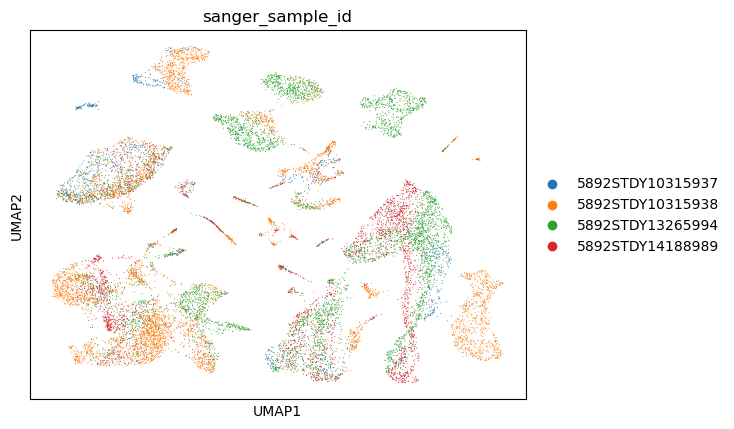

In [55]:
# Step 1: Scale the data
sc.pp.scale(subset, max_value=10)

# Step 2: PCA
sc.tl.pca(subset)

# Step 3: Compute neighbors
sc.pp.neighbors(subset)

# Step 4: Compute UMAP
sc.tl.umap(subset)

# Step 5: Now plot
sc.pl.umap(
    subset,
    color=["sanger_sample_id"],
    size=2,
)

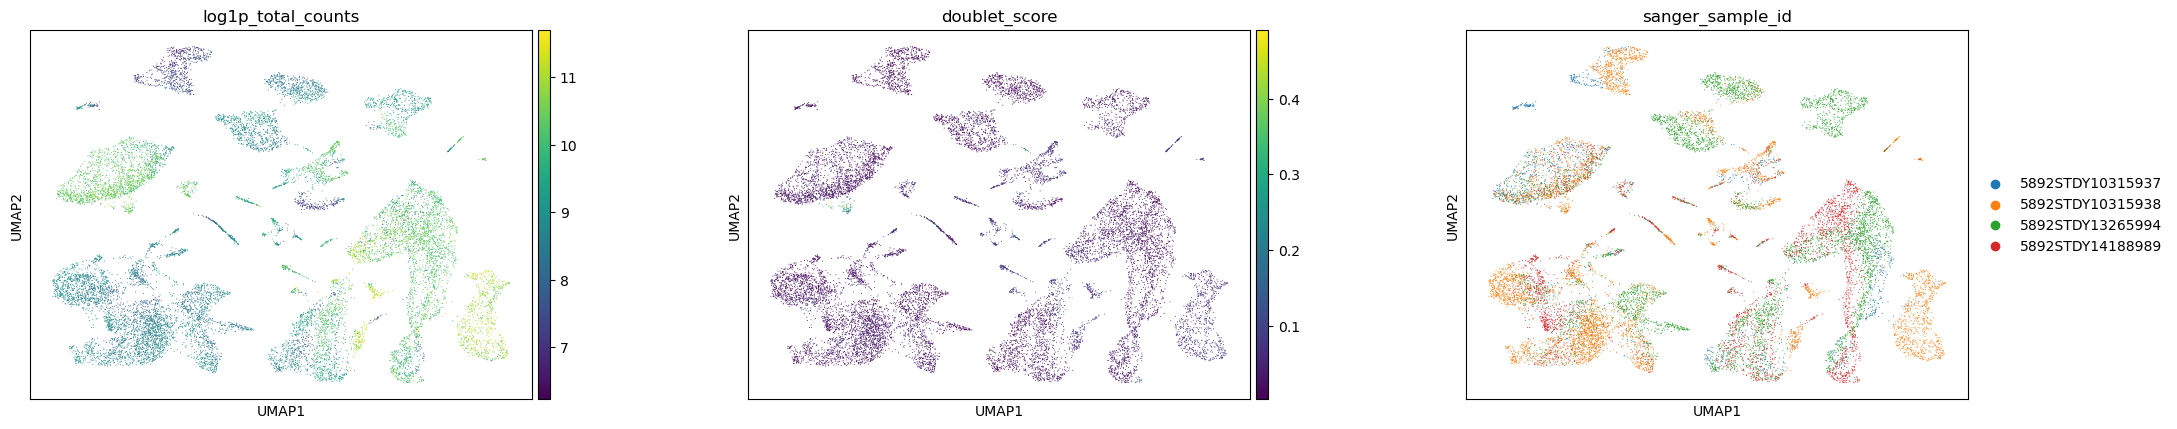

In [59]:
# Plot technical variables
sc.pl.umap(
    subset,
    color=["log1p_total_counts", "doublet_score", "sanger_sample_id"],
    size=2,
    wspace=0.3
)

In [ ]:
#Additional QC

In [61]:
idx = (subset.obs.pct_counts_mt < 5) & (subset.obs.doublet_score < 0.3) & (subset.obs.total_counts > 250)

In [62]:
subset = subset[idx]

In [63]:
subset

View of AnnData object with n_obs × n_vars = 14989 × 33538
    obs: 'sanger_sample_id', 'tissue', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'gene_symbols', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'sanger_sample_id_colors'
    obsm: 'X_pca', 'X_umap'
    va

In [67]:
sc.pp.highly_variable_genes(subset, n_top_genes=2000, batch_key="sanger_sample_id")

In [69]:
sc.tl.pca(subset)

In [71]:
sc.pp.neighbors(subset)

In [72]:
sc.tl.umap(subset)

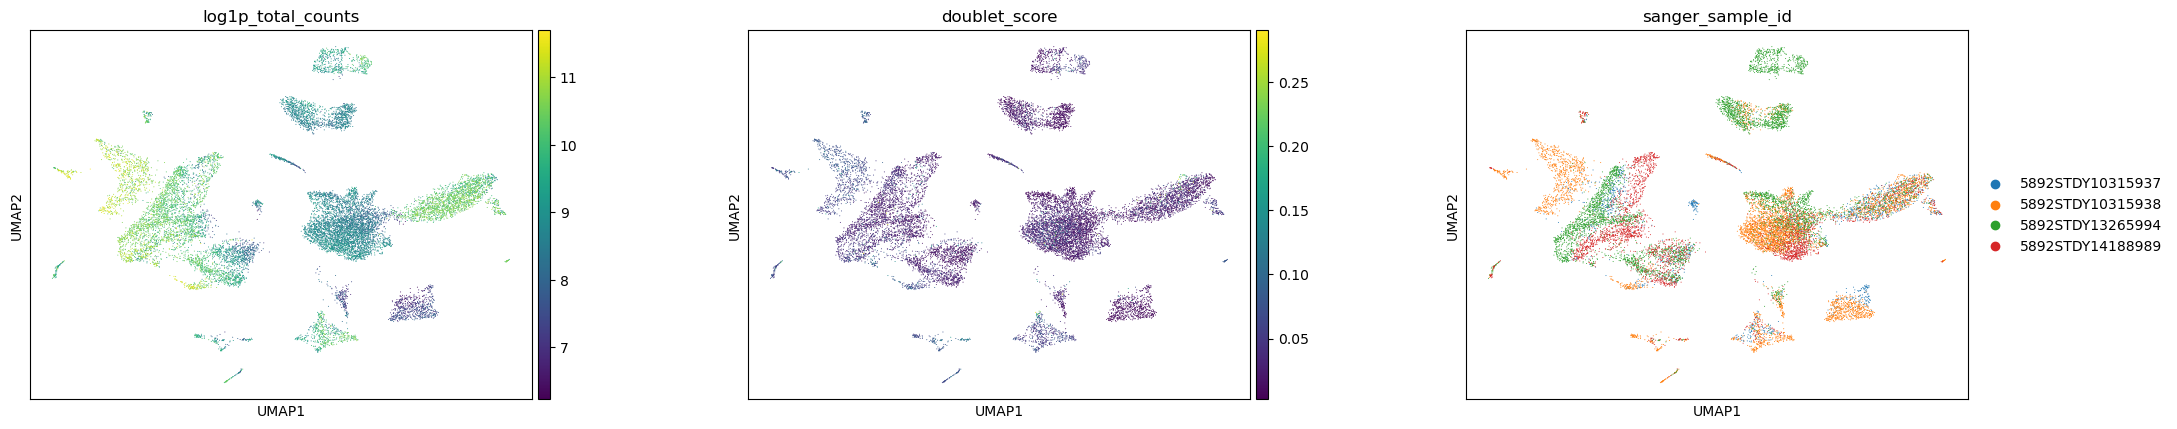

In [74]:
sc.pl.umap(
    subset,
    color=["log1p_total_counts", "doublet_score", "sanger_sample_id"],
    size=2,
    wspace=0.3
)

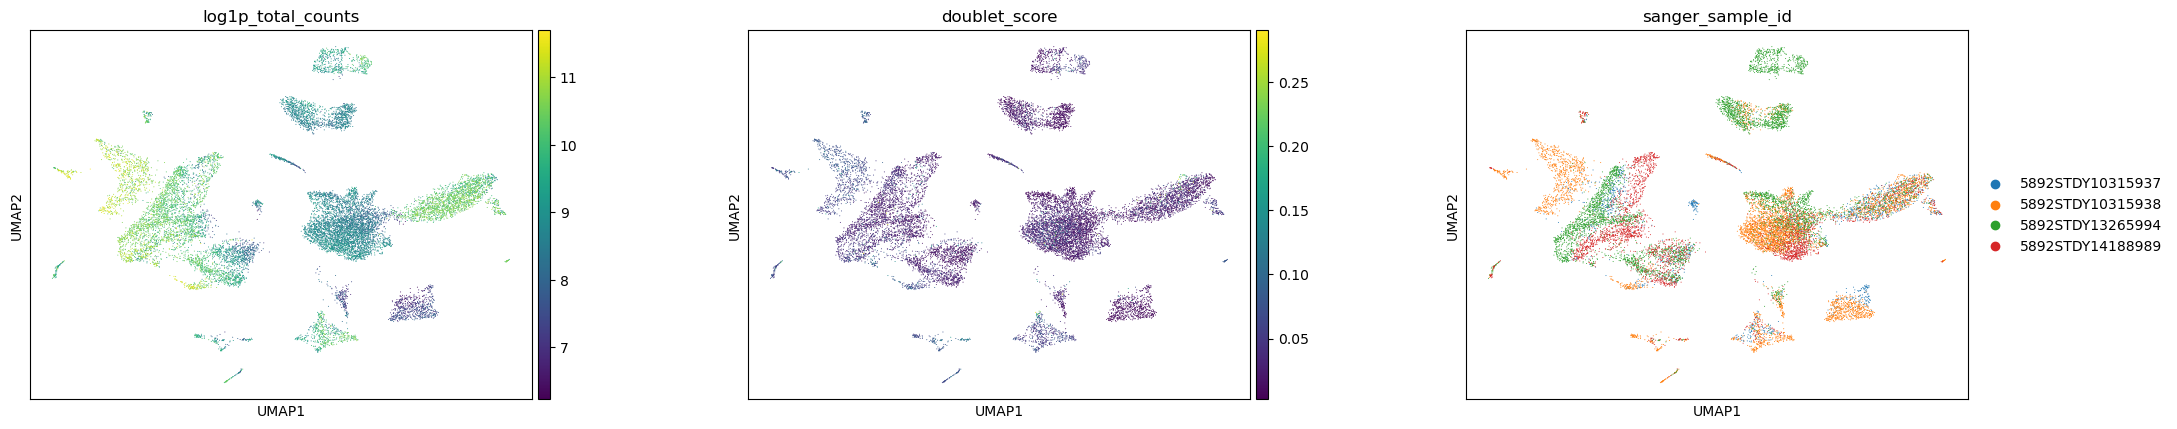

In [75]:
# Plot technical variables
sc.pl.umap(
    subset,
    color=["log1p_total_counts", "doublet_score", "sanger_sample_id"],
    size=2,
    wspace=0.3
)

In [80]:
import scvi

In [89]:
scvi.model.SCVI.setup_anndata(subset, layer="counts", batch_key="sanger_sample_id")

In [ ]:
model.train(max_epochs=900)

In [91]:
subset.obsm["X_scVI"] = model.get_latent_representation()

In [93]:
subset

AnnData object with n_obs × n_vars = 14989 × 33538
    obs: 'sanger_sample_id', 'tissue', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', '_scvi_batch', '_scvi_labels'
    var: 'gene_symbols', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'sanger_sample_id_colors', '_scvi_uui

In [95]:
sc.pp.neighbors(subset, use_rep="X_scVI")

In [96]:
sc.tl.umap(subset)

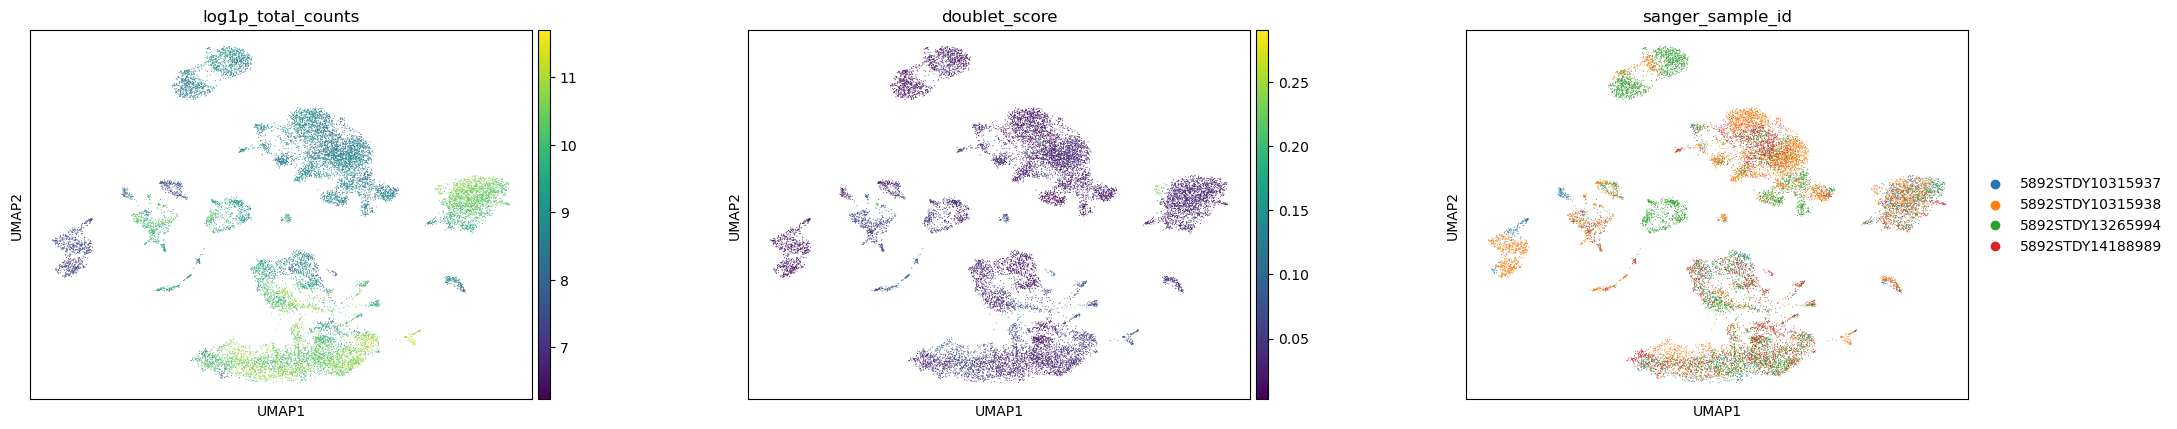

In [97]:
sc.pl.umap(
    subset,
    color=["log1p_total_counts", "doublet_score", "sanger_sample_id"],
    size=2,
    wspace=0.3
)

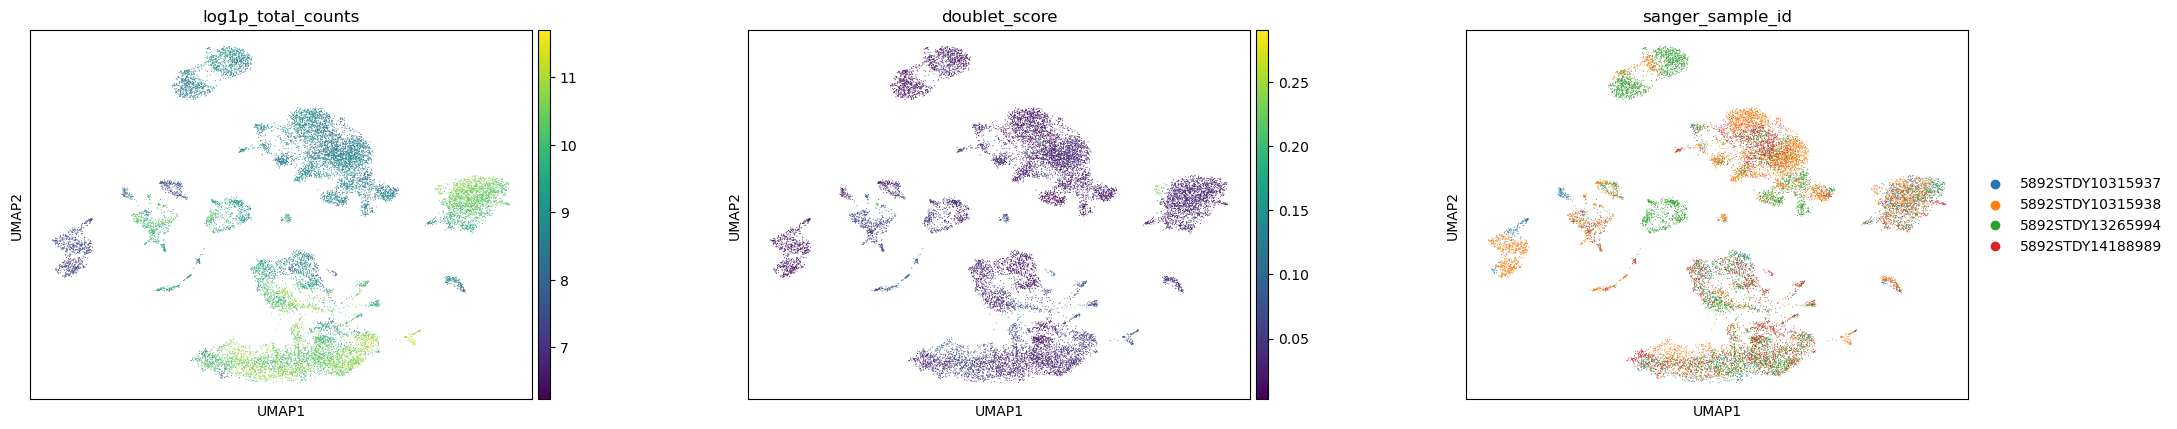

In [98]:
# Plot technical variables
sc.pl.umap(
    subset,
    color=["log1p_total_counts", "doublet_score", "sanger_sample_id"],
    size=2,
    wspace=0.3
)

In [99]:
subset.X = subset.layers['counts']

In [ ]:
sc.pp.normalize_total(subset, target_sum=10000)

In [100]:
sc.pp.log1p(subset)

In [107]:
pangi_model = models.Model.load('Adult_Human_Intestine.pkl')

In [110]:
pangi_model

CellTypist model with 44 cell types and 7827 features
    date: 2023-02-23 11:12:11.155109
    details: cell types from the adult human intestine
    source: TBD
    version: v1
    cell types: Arterial endothelial cells, BEST4+ enterocytes, ..., gamma-delta T cells
    features: A1BG, A1CF, ..., ZZEF1

In [111]:
pangi_model.cell_types

array(['Arterial endothelial cells', 'BEST4+ enterocytes',
       'Capillary endothelial cells', 'Colonocytes', 'Cycling B cells',
       'Cycling/Secretory TA', 'DC1', 'DC2', 'Enterocytes',
       'Enteroendocrine cells', 'Follicular B cells',
       'Follicular helper T cells', 'Germinal center B cells', 'Glia',
       'Goblet cells', 'ILC', 'Immature goblet cells',
       'Intestinal macrophages', 'Lymphatic endothelial cells',
       'Macrophages', 'Mast cells', 'Memory B cells', 'Monocytes',
       'Myofibroblasts', 'NK cells', 'Naive B cells', 'Paneth',
       'Pericytes', 'Plasma cells', 'Regulatory T cells', 'Stem cells',
       'Stromal 1', 'Stromal 2', 'Stromal 3', 'TA',
       'Tcm/Naive helper T cells', 'Tem/Effector helper T cells',
       'Tem/Trm cytotoxic T cells', 'Trm cytotoxic T cells', 'Tuft cells',
       'Type 1 helper T cells', 'Type 17 helper T cells',
       'Venous endothelial cells', 'gamma-delta T cells'], dtype=object)

In [114]:
# Restore raw counts first
subset.X = subset.layers["counts"].copy()

# Normalize to 10,000 counts per cell (target_sum=1e4)
sc.pp.normalize_total(subset, target_sum=1e4)

# Log1p transform
sc.pp.log1p(subset)

# Run celltypist
predictions = celltypist.annotate(subset, model=pangi_model, majority_voting=True)
subset = predictions.to_adata()

# Plot results on UMAP
sc.pl.umap(subset, color=["majority_voting"], size=2, legend_loc="on data")

🔬 Input data has 14989 cells and 33538 genes
🔗 Matching reference genes in the model


ValueError: 🛑 No features overlap with the model. Please provide gene symbols

In [116]:
print(subset.var.columns)
print(subset.var.head())

Index(['gene_symbols', 'feature_types', 'mt', 'ribo', 'hb',
       'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts',
       'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts',
       'highly_variable', 'means', 'dispersions', 'dispersions_norm',
       'highly_variable_nbatches', 'highly_variable_intersection', 'mean',
       'std'],
      dtype='object')
                gene_symbols    feature_types     mt   ribo     hb  \
ENSG00000243485  MIR1302-2HG  Gene Expression  False  False  False   
ENSG00000237613      FAM138A  Gene Expression  False  False  False   
ENSG00000186092        OR4F5  Gene Expression  False  False  False   
ENSG00000238009   AL627309.1  Gene Expression  False  False  False   
ENSG00000239945   AL627309.3  Gene Expression  False  False  False   

                 n_cells_by_counts  mean_counts  log1p_mean_counts  \
ENSG00000243485                  1     0.000066           0.000066   
ENSG00000237613                  0     0.000000           0.000

🔬 Input data has 14989 cells and 33538 genes
🔗 Matching reference genes in the model
🧬 7827 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


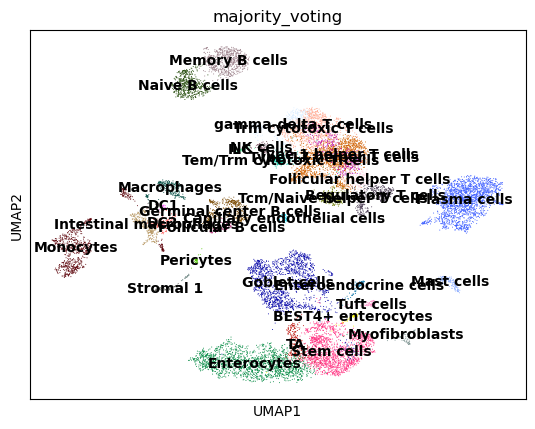

In [117]:
# Set gene symbols as the var_names index
subset.var_names = subset.var["gene_symbols"]
subset.var_names_make_unique()

# Restore raw counts and re-normalize
subset.X = subset.layers["counts"].copy()
sc.pp.normalize_total(subset, target_sum=1e4)
sc.pp.log1p(subset)

# Now retry celltypist
predictions = celltypist.annotate(subset, model=pangi_model, majority_voting=True)
subset = predictions.to_adata()

# Plot
sc.pl.umap(subset, color=["majority_voting"], size=2, legend_loc="on data")

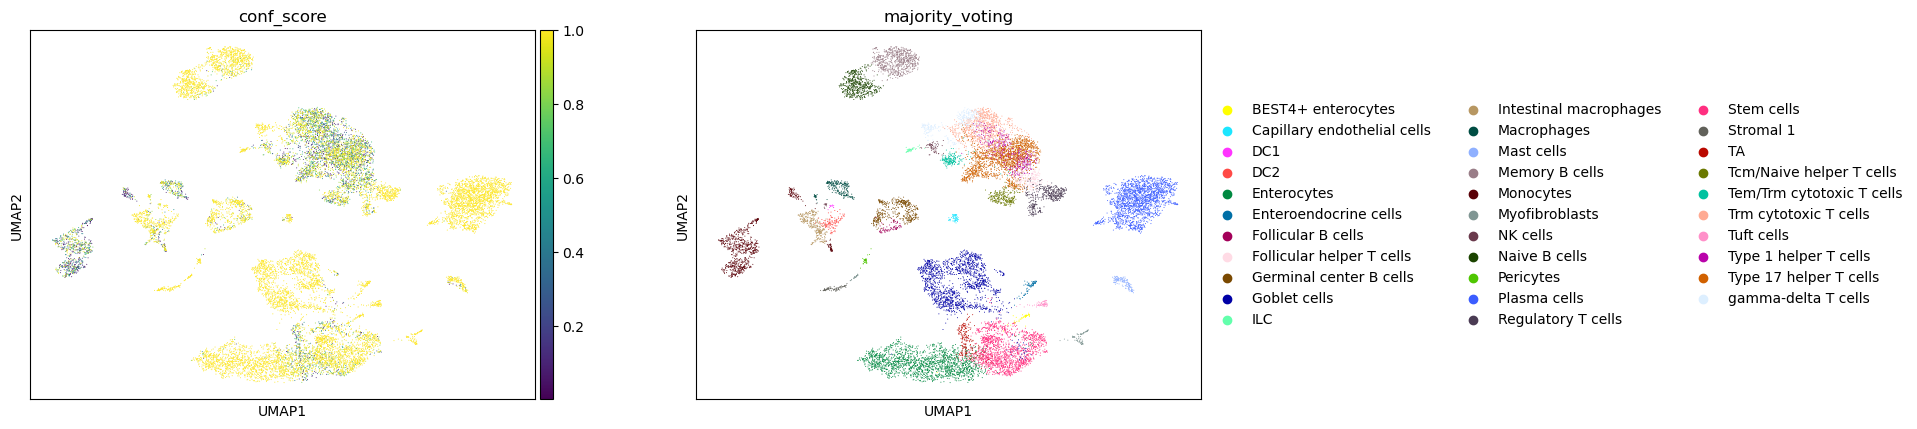

In [119]:
sc.pl.umap(
    subset,
    color=["conf_score", "majority_voting"],
    size=2,
    wspace=0.2
)

In [121]:
broad_markers = [
    "EPCAM",
    "LUM",
    "COL13A1",
    "RGS5",
    "MYH11",
    "PECAM1",
    "CCL21",
    "CD3D",
    "MS4A1",
    "TNFRSF17",
    "G0S2",
    "C1QA",
    "CD1C",
    "CLEC4C",
    "MS4A2",
    "MUC6",
    "MUC5AC",
    "BPIFB1",
    "AQP5",
    "S100B",
    "MKI67",
]

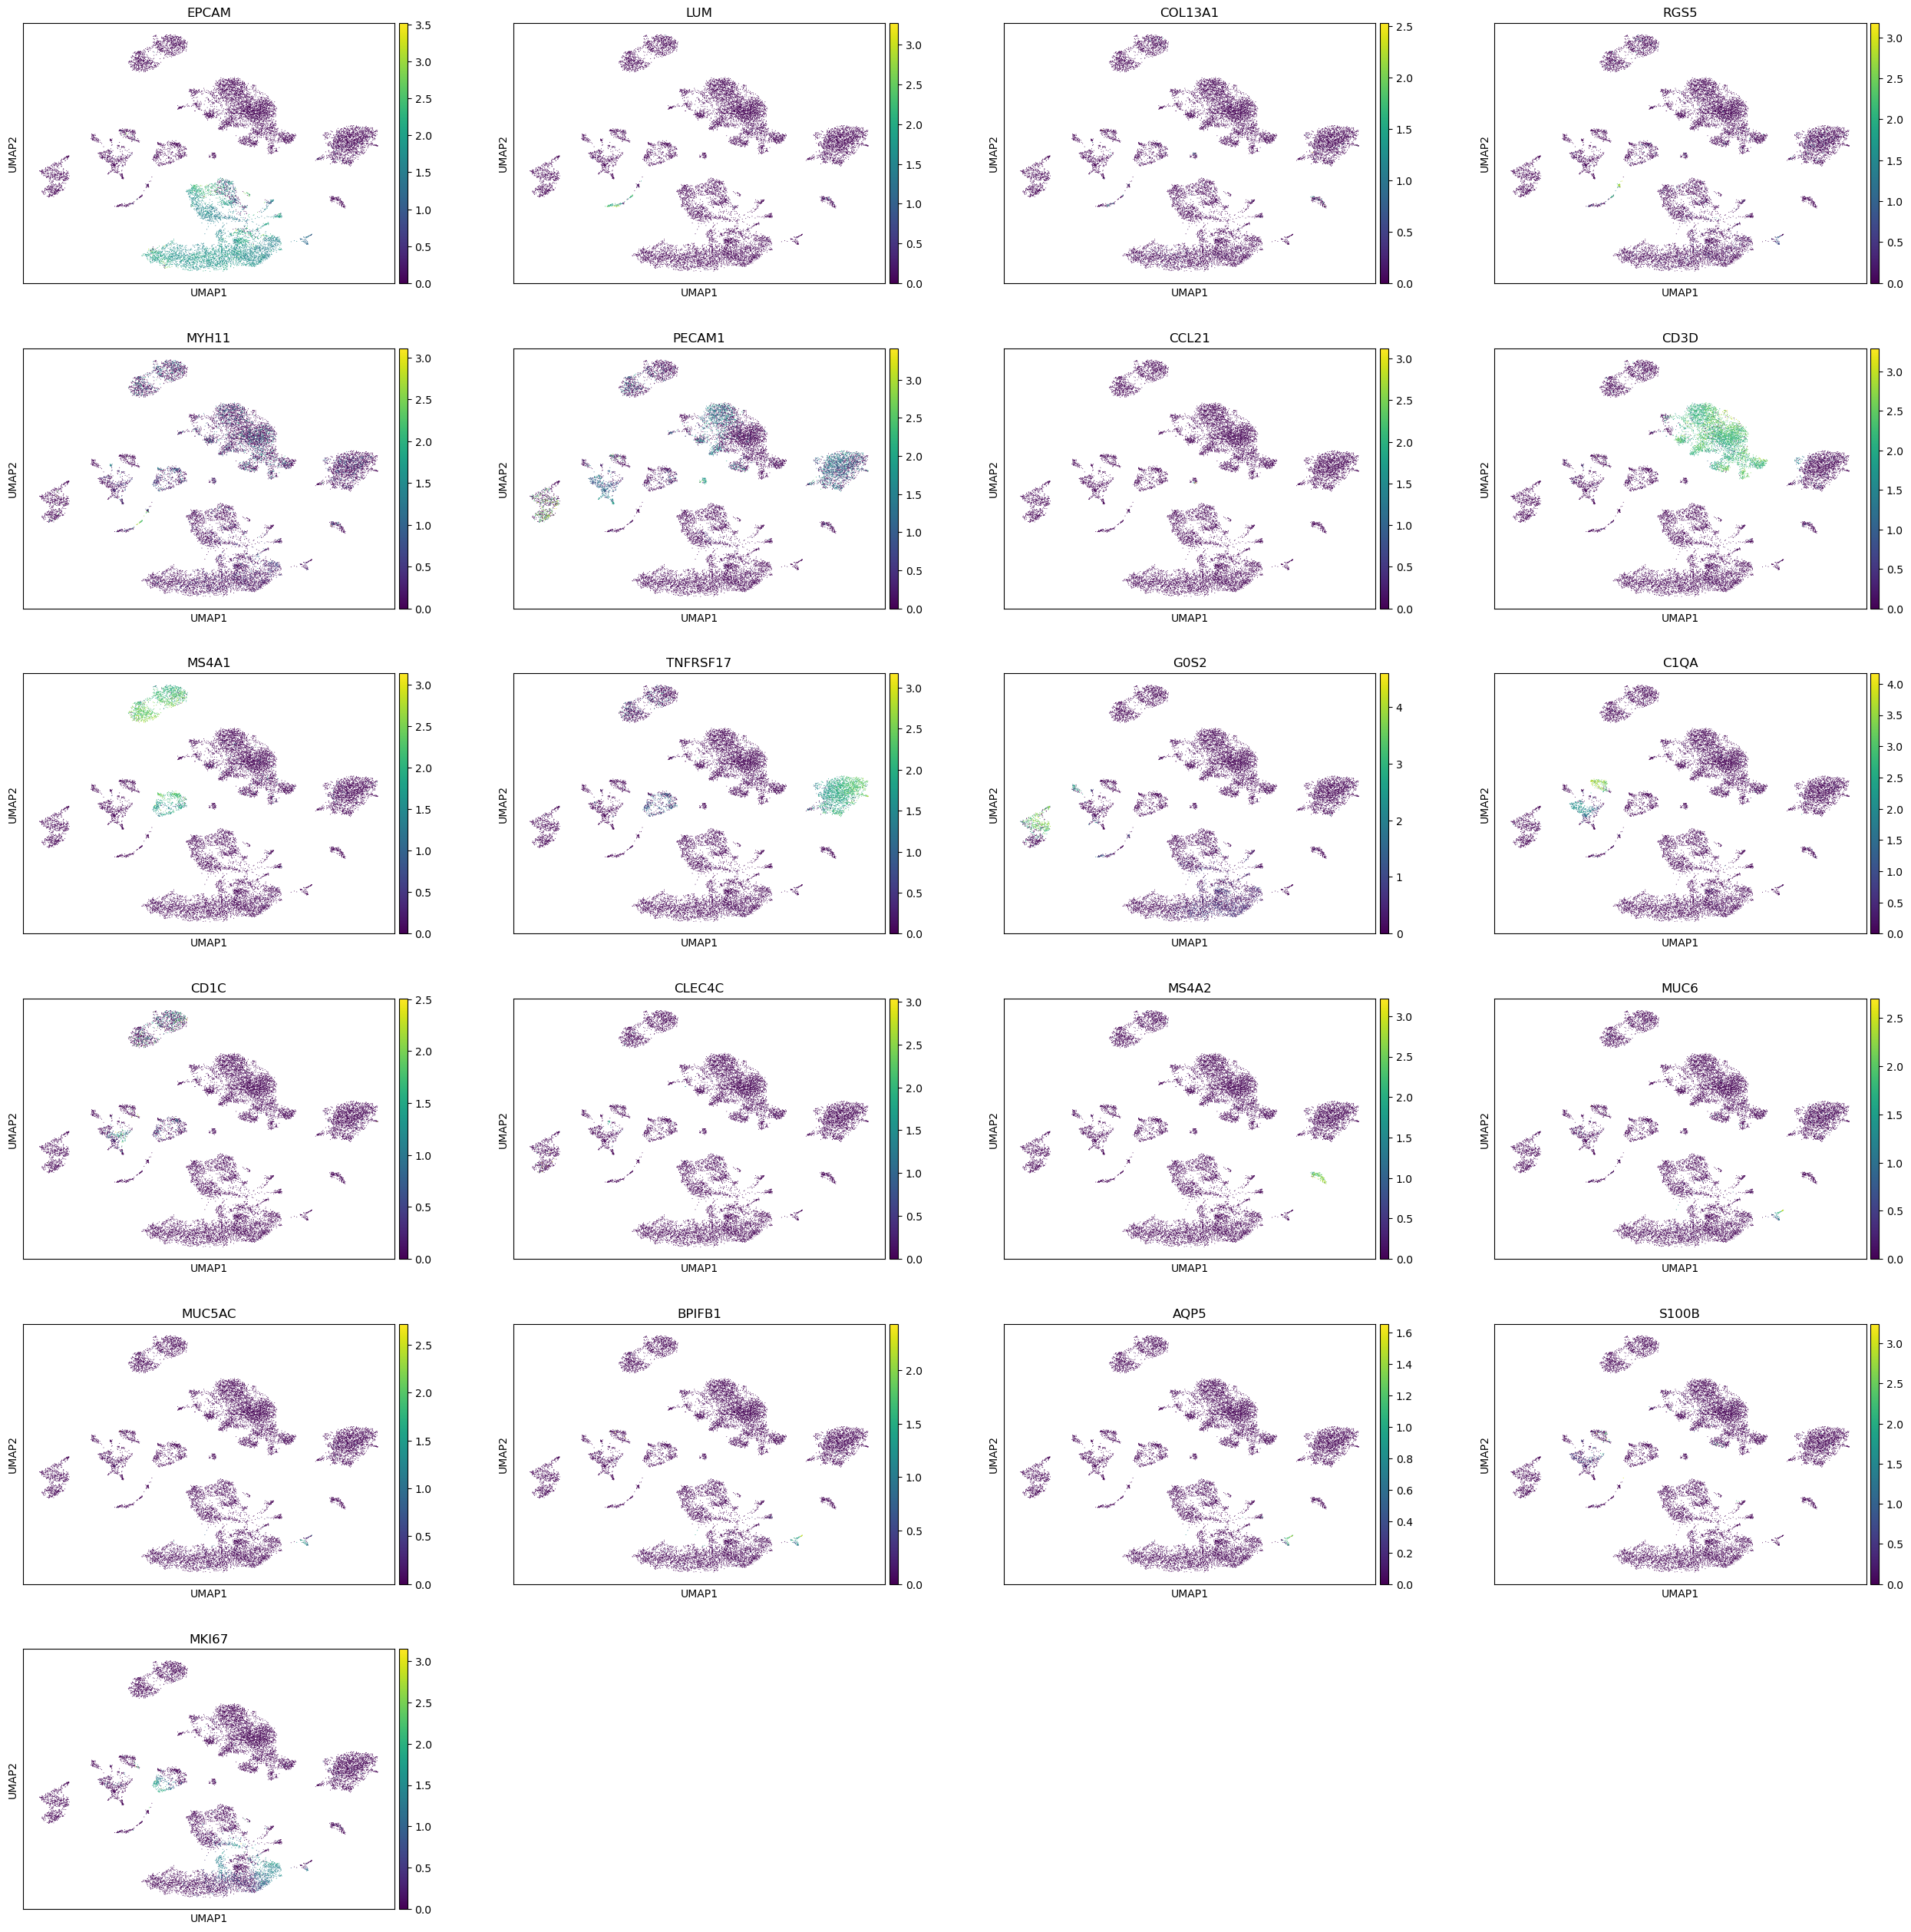

In [122]:
sc.pl.umap(
    subset,
    color=broad_markers,
    size=2,
    wspace=0.2
)

In [124]:
sc.pp.neighbors(subset, use_rep="X_scVI")

In [125]:
sc.tl.leiden(subset)

In [126]:
subset

AnnData object with n_obs × n_vars = 14989 × 33538
    obs: 'sanger_sample_id', 'tissue', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', '_scvi_batch', '_scvi_labels', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score', 'leiden'
    var: 'gene_symbols', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'scrublet',

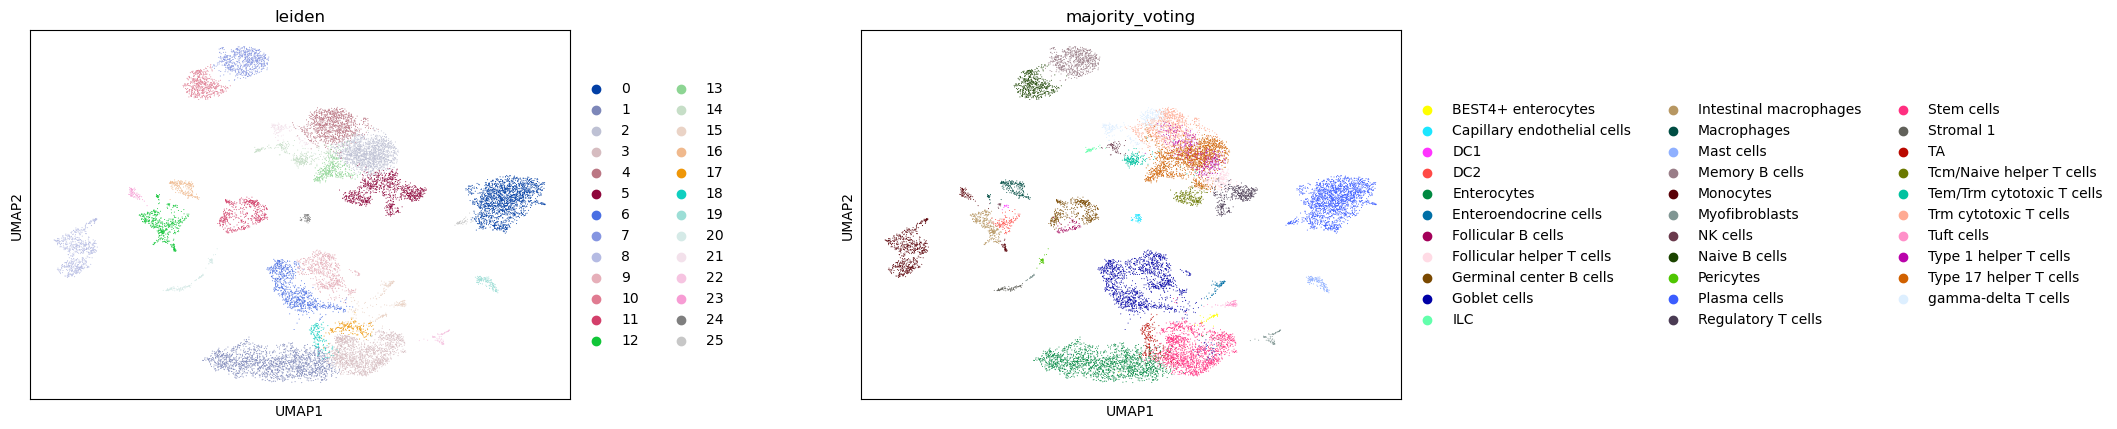

In [127]:
sc.pl.umap(
    subset,
    color=["leiden", "majority_voting"],
    size=2,
    wspace=0.4
)